# Legendre polynomials notebook

Legendre polynomials are solutions to Legendre's equation:

$$
(1-x^2)y'' - 2xy' + l(l+1)y = 0
$$

where $l$ is a non-negative integer and $-1 \leq x \leq 1$. The general solution is a linear combination of Legendre functions of the first kind ($P_l(x)$) and of the second kind ($Q_l(x)$):

$$
y(x) = AP_l(x) + BQ_l(x)
$$

## Legendre polynomials of the first kind

The first few Legendre polynomials of the first kind are:

$$
P_0(x) = 1, \qquad P_1(x) = x, \qquad P_2(x) = \frac{1}{2}(3x^2-1), \qquad P_3(x) = \frac{1}{2}(5x^3-3x)
$$

Properties of Legendre polynomials of the first kind:
- $P_l(x)$ is a polynomial of degree $l$.
- $P_l(1) = 1$ and $P_l(-1) = (-1)^l$ for all values of $l$.
- $P_l(x)$ is even when $l$ is even and odd when $l$ is odd.
- $P_l(x)$ has exactly $l$ zeros between $-1$ and $1$.

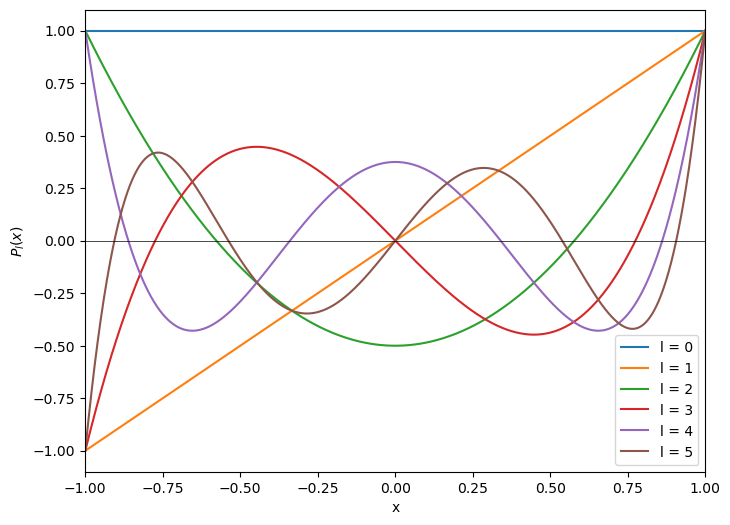

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy as sp

# Constants
orders = [0, 1, 2, 3, 4, 5]

x = np.linspace(-1, 1, num = 1000)

fig, axes = plt.subplots(1, 1, figsize=(8,6))
for l in orders:
    axes.plot(x, sp.special.eval_legendre(l, x), label=f"l = {l}")
axes.axhline(0, color='k', linewidth=0.5)
axes.legend(loc="lower right")
axes.set_ylabel(r"$P_l(x)$")
axes.set_xlabel("x")
axes.set_xlim(-1, 1)

plt.show()


## Legendre functions of the second kind

The Legendre functions of the second kind are **not** polynomials. The first two are:

$$
Q_0(x) = \frac{1}{2}\ln\left(\frac{1+x}{1-x}\right), \qquad Q_1(x) = \frac{x}{2}\ln\left(\frac{1+x}{1-x}\right) - 1
$$

The others can be found from the recursion relation:

$$
(l+1)Q_{l+1}(x) = (2l+1)xQ_l(x) - lQ_{l-1}(x)
$$

Properties of Legendre functions of the second kind:
- For all values of $l$, $Q_l(x)$ diverges at $x = \pm 1$: $\lim_{x\rightarrow 1^-} Q_l(x) = +\infty$.
- $Q_l(x)$ is odd when $l$ is even and even when $l$ is odd (the opposite of $P_l(x)$).

Because $Q_l(x)$ diverges at $x=\pm 1$, it is usually thrown out ($B = 0$) in physics problems where $x = \cos\theta$ and the solution must be finite at the north and south poles ($\theta = 0$ and $\theta = \pi$).

Below, we stop the plot at $|x| = 0.99$ to avoid the divergence.

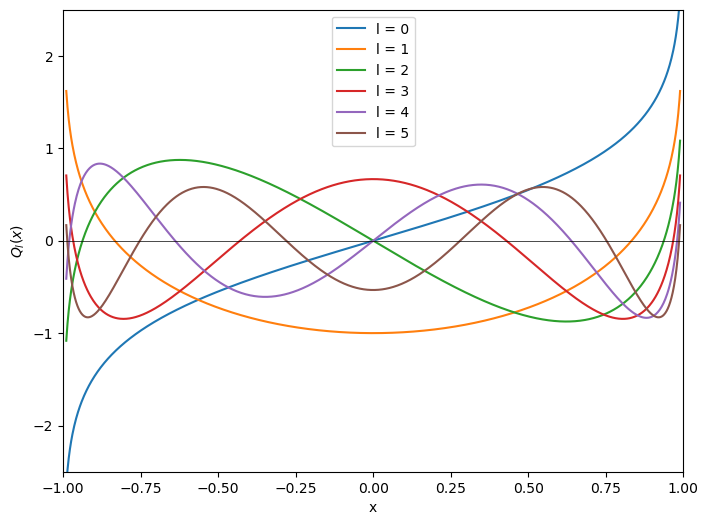

In [2]:
# Legendre functions of the second kind using the recursion relation
def legendre_Q(l, x):
    Q0 = 0.5*np.log((1+x)/(1-x))
    if l == 0:
        return Q0
    Q1 = x*Q0 - 1
    for n in range(1, l):
        Q0, Q1 = Q1, ((2*n+1)*x*Q1 - n*Q0)/(n+1)
    return Q1

x = np.linspace(-0.99, 0.99, num = 1000)

fig, axes = plt.subplots(1, 1, figsize=(8,6))
for l in orders:
    axes.plot(x, legendre_Q(l, x), label=f"l = {l}")
axes.axhline(0, color='k', linewidth=0.5)
axes.legend(loc="upper center")
axes.set_ylabel(r"$Q_l(x)$")
axes.set_xlabel("x")
axes.set_xlim(-1, 1)
axes.set_ylim(-2.5, 2.5)

plt.show()


## Legendre polynomials on a sphere

Legendre polynomials appear when solving Laplace's equation in spherical coordinates for problems with azimuthal symmetry (no dependence on $\phi$). In that case, the angular part of the solution is:

$$
\Theta(\theta) = P_l(\cos\theta)
$$

with $x = \cos\theta$. As $\theta$ goes from $0$ (north pole) to $\pi$ (south pole), $x$ goes from $1$ to $-1$.

Below, we color a sphere of fixed radius $R = 1$ according to the value of $P_l(\cos\theta)$ for $l = 0, 1, \ldots, 8$. Red is positive, blue is negative, and white is zero. Notice that:
- The pattern does not depend on $\phi$ (it is the same all the way around the $z$ axis).
- The zeros of $P_l(\cos\theta)$ are circles of constant latitude. There are $l$ of them.
- Even $l$ are symmetric between the northern and southern hemispheres. Odd $l$ change sign.

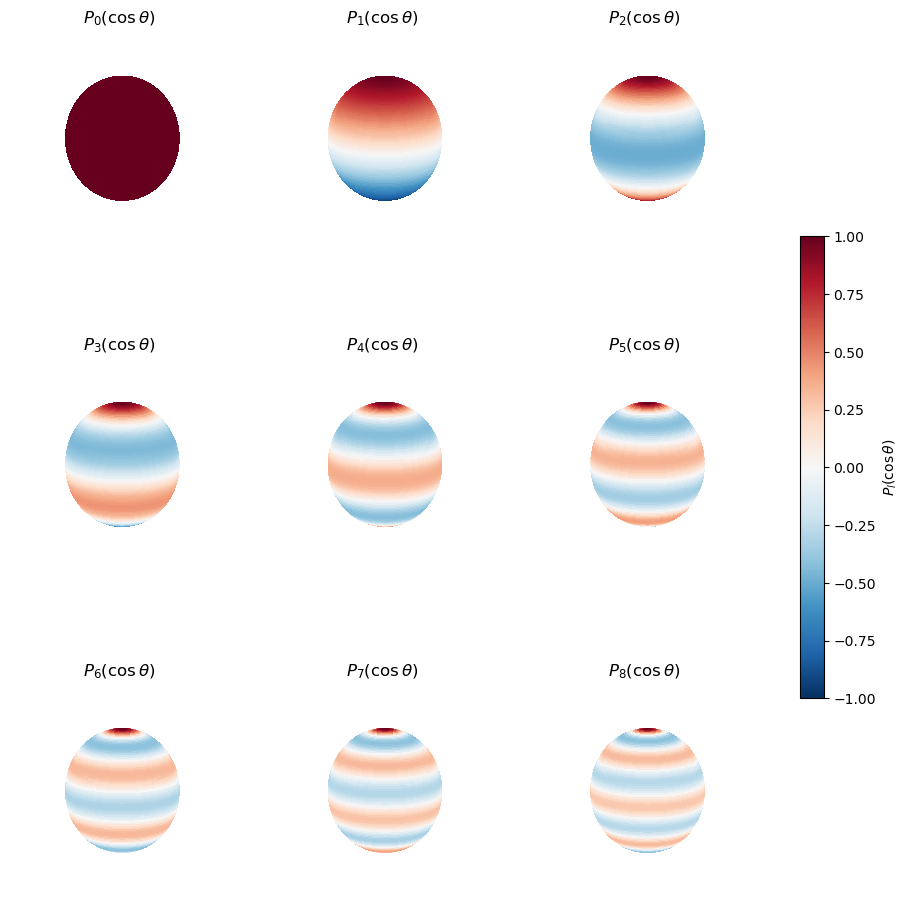

In [3]:
# Constants
R = 1.0
N = 100

# Create theta and phi axis
theta = np.linspace(0, np.pi, N)
phi = np.linspace(0, 2*np.pi, N)
THETA, PHI = np.meshgrid(theta, phi)

# Create x, y, and z axis
X = R*np.sin(THETA)*np.cos(PHI)
Y = R*np.sin(THETA)*np.sin(PHI)
Z = R*np.cos(THETA)

# Color map from -1 to 1
cmap = plt.get_cmap("RdBu_r")
norm = plt.Normalize(vmin=-1, vmax=1)

# Create figure
fig = plt.figure(figsize=(12, 12))

for l in range(9):
    ax = fig.add_subplot(3, 3, l+1, projection="3d")

    Pl = sp.special.eval_legendre(l, np.cos(THETA))

    ax.plot_surface(X, Y, Z, facecolors=cmap(norm(Pl)), rstride=1, cstride=1,
                    linewidth=0, antialiased=False, shade=False)

    ax.set_title(fr"$P_{l}(\cos\theta)$")
    ax.set_box_aspect([1, 1, 1])
    ax.azim = -60
    ax.elev = 15
    ax.set_axis_off()

# Shared color bar
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
fig.colorbar(sm, ax=fig.axes, shrink=0.5, label=r"$P_l(\cos\theta)$")

plt.show()
